# SignBridge AI — WL-BISINDO
Tahap notebook ini mencakup persiapan dataset, EDA, preprocessing, ekstraksi landmark MediaPipe, pembagian data, dan definisi model LSTM. **Training dan evaluasi belum termasuk.**

> Dataset WL-BISINDO digunakan untuk kosakata BISINDO, bukan Kata Kolok. Periksa struktur folder dan label yang ditemukan sebelum melanjutkan.

## 1. Import Libraries

In [21]:
# Instalasi (jalankan di terminal VS Code, bukan di cell ini):
# python -m pip install opencv-python mediapipe tensorflow scikit-learn pandas numpy matplotlib tqdm

from pathlib import Path
import re
import random, warnings, pickle
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import mediapipe as mp
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, confusion_matrix, top_k_accuracy_score
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
print("TensorFlow:", tf.__version__, "| OpenCV:", cv2.__version__, "| MediaPipe:", mp.__version__)

TensorFlow: 2.19.1 | OpenCV: 4.12.0 | MediaPipe: 0.10.14


## 2. Konfigurasi Path dan Parameter

In [2]:
# Sesuaikan path dengan lokasi dataset yang sudah diekstrak.
PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATASET_DIR = PROJECT_DIR / "data" / "raw" / "WL-BISINDO"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed" / "landmarks"
MODEL_DIR = PROJECT_DIR / "models"
for folder in (PROCESSED_DIR, MODEL_DIR):
    folder.mkdir(parents=True, exist_ok=True)

NUM_FRAMES = 30
TEST_SIZE = 0.20
VAL_SIZE_FROM_REMAINDER = 0.20
VIDEO_EXTENSIONS = {".mp4", ".avi", ".mov", ".mkv", ".webm"}
MIN_DETECTION_CONFIDENCE = 0.5
MIN_TRACKING_CONFIDENCE = 0.5

print("Dataset path:", DATASET_DIR.resolve())
print("Folder ditemukan:", DATASET_DIR.exists())

Dataset path: C:\Users\Ryan\Documents\JURNEY KAMPUS\S7\SISTEM CERDAS\proyek\bisindo\data\raw\WL-BISINDO
Folder ditemukan: False


## 3. Memuat Dataset WL-BISINDO

In [3]:
# Lokasi folder dataset
video_paths = sorted(
    p for p in DATASET_DIR.rglob("*.mp4")
    if p.is_file()
)

# Pola nama file:
# signer0_label0_sample1.mp4
pattern = re.compile(
    r"signer(\d+)_label(\d+)_sample(\d+)\.mp4$",
    re.IGNORECASE
)

records = []
invalid_files = []

for path in video_paths:
    match = pattern.fullmatch(path.name)

    if match:
        signer_id = int(match.group(1))
        label_id = int(match.group(2))
        sample_id = int(match.group(3))

        records.append({
            "video_path": str(path),
            "signer_id": signer_id,
            "label_id": label_id,
            "sample_id": sample_id
        })
    else:
        invalid_files.append(path.name)

df = pd.DataFrame(records)

if df.empty:
    raise ValueError(
        "Tidak ada file yang sesuai dengan pola nama WL-BISINDO. "
        "Periksa DATASET_DIR dan nama file."
    )

print("Jumlah video valid:", len(df))
print("Jumlah signer:", df["signer_id"].nunique())
print("Jumlah label:", df["label_id"].nunique())
print("Jumlah file tidak sesuai pola:", len(invalid_files))

display(df.head(10))

Jumlah video valid: 1600
Jumlah signer: 5
Jumlah label: 32
Jumlah file tidak sesuai pola: 0


,video_path,signer_id,label_id,sample_id
0,c:\Users\Ryan\Documents\JURNEY KAMPUS\S7\SISTE...,0,0,1
1,c:\Users\Ryan\Documents\JURNEY KAMPUS\S7\SISTE...,0,0,10
2,c:\Users\Ryan\Documents\JURNEY KAMPUS\S7\SISTE...,0,0,2
3,c:\Users\Ryan\Documents\JURNEY KAMPUS\S7\SISTE...,0,0,3
4,c:\Users\Ryan\Documents\JURNEY KAMPUS\S7\SISTE...,0,0,4
5,c:\Users\Ryan\Documents\JURNEY KAMPUS\S7\SISTE...,0,0,5
6,c:\Users\Ryan\Documents\JURNEY KAMPUS\S7\SISTE...,0,0,6
7,c:\Users\Ryan\Documents\JURNEY KAMPUS\S7\SISTE...,0,0,7
8,c:\Users\Ryan\Documents\JURNEY KAMPUS\S7\SISTE...,0,0,8
9,c:\Users\Ryan\Documents\JURNEY KAMPUS\S7\SISTE...,0,0,9


## 4. Exploratory Data Analysis (EDA)

,jumlah_video
label_id,
0,50
1,50
2,50
3,50
4,50
5,50
6,50
7,50
8,50


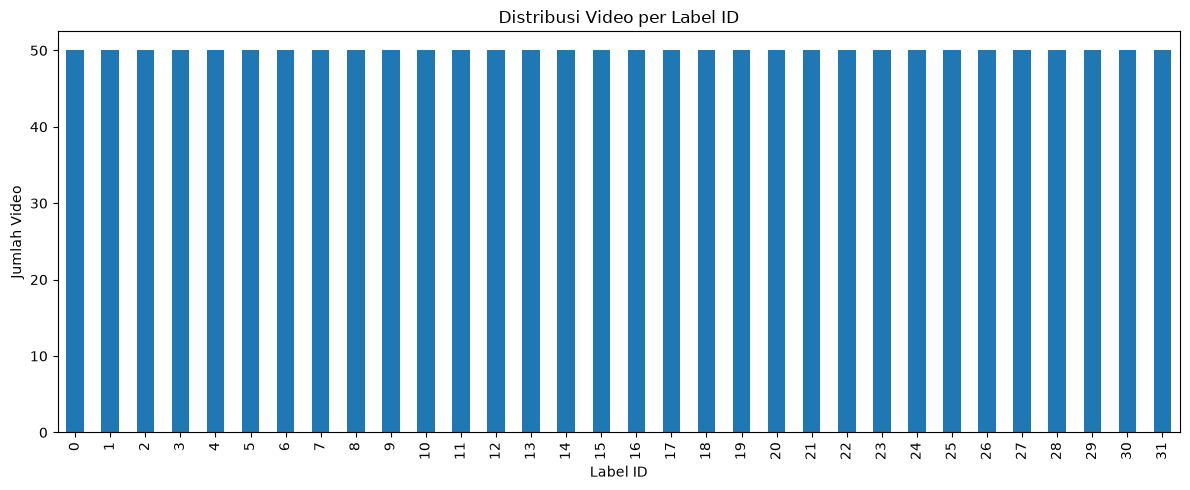

In [4]:

class_counts = df["label_id"].value_counts().sort_index()

display(
    class_counts.rename("jumlah_video").to_frame()
)

class_counts.plot(
    kind="bar",
    figsize=(12, 5),
    title="Distribusi Video per Label ID"
)

plt.xlabel("Label ID")
plt.ylabel("Jumlah Video")
plt.tight_layout()
plt.show()

## 5. Visualisasi Sampel Video

Signer ID: 1
Label ID: 8
Sample ID: 6


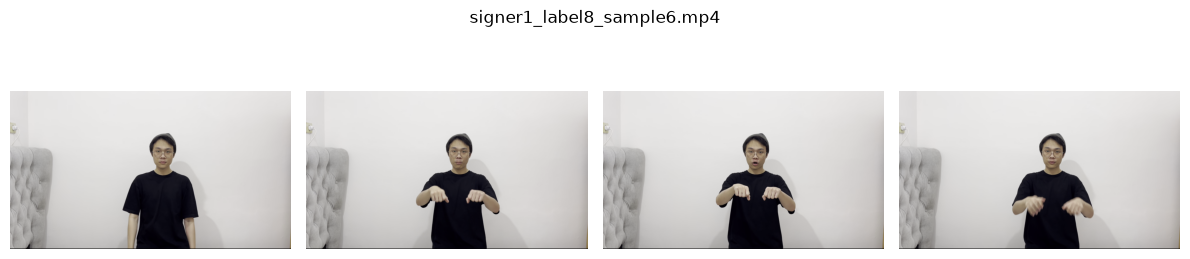

In [5]:
def show_video_frames(video_path, n_frames=6):
    cap = cv2.VideoCapture(str(video_path))
    if not cap.isOpened():
        cap.release()
        print("Video tidak dapat dibuka:", video_path)
        return
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if total < 1:
        cap.release(); print("Video tidak memiliki frame."); return
    indices = np.linspace(0, total - 1, min(n_frames, total), dtype=int)
    frames = []
    for idx in indices:
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx))
        ok, frame = cap.read()
        if ok: frames.append(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    cap.release()
    if not frames:
        print("Tidak ada frame terbaca."); return
    fig, axes = plt.subplots(1, len(frames), figsize=(3*len(frames), 3))
    if len(frames) == 1: axes = [axes]
    for ax, frame in zip(axes, frames):
        ax.imshow(frame); ax.axis("off")
    fig.suptitle(Path(video_path).name); plt.tight_layout(); plt.show()


sample = df.sample(1, random_state=SEED).iloc[0]

print("Signer ID:", sample["signer_id"])
print("Label ID:", sample["label_id"])
print("Sample ID:", sample["sample_id"])

show_video_frames(sample["video_path"])

## 6. Validasi Dataset

In [6]:
validation_rows = []

for row in tqdm(
    df.itertuples(index=False),
    total=len(df),
    desc="Memeriksa video"
):
    cap = cv2.VideoCapture(row.video_path)

    opened = cap.isOpened()
    frame_count = int(
        cap.get(cv2.CAP_PROP_FRAME_COUNT)
    ) if opened else 0

    fps = float(
        cap.get(cv2.CAP_PROP_FPS)
    ) if opened else 0.0

    cap.release()

    validation_rows.append({
        "video_path": row.video_path,
        "signer_id": row.signer_id,
        "label_id": row.label_id,
        "sample_id": row.sample_id,
        "is_readable": bool(opened and frame_count > 0),
        "frame_count": frame_count,
        "fps": fps
    })

validation_df = pd.DataFrame(validation_rows)

display(validation_df.head())

print(
    "Video bermasalah:",
    int((~validation_df["is_readable"]).sum())
)

df = validation_df.loc[
    validation_df["is_readable"]
].reset_index(drop=True)

print("Jumlah video valid:", len(df))

Memeriksa video: 100%|██████████| 1600/1600 [00:14<00:00, 111.65it/s]


,video_path,signer_id,label_id,sample_id,is_readable,frame_count,fps
0,c:\Users\Ryan\Documents\JURNEY KAMPUS\S7\SISTE...,0,0,1,True,81,26.413043
1,c:\Users\Ryan\Documents\JURNEY KAMPUS\S7\SISTE...,0,0,10,True,88,26.925038
2,c:\Users\Ryan\Documents\JURNEY KAMPUS\S7\SISTE...,0,0,2,True,67,28.309859
3,c:\Users\Ryan\Documents\JURNEY KAMPUS\S7\SISTE...,0,0,3,True,73,27.703985
4,c:\Users\Ryan\Documents\JURNEY KAMPUS\S7\SISTE...,0,0,4,True,84,27.391304


Video bermasalah: 0
Jumlah video valid: 1600


## 7. Preprocessing Video

In [9]:
def sample_video_frames(video_path, num_frames=NUM_FRAMES):
    cap = cv2.VideoCapture(str(video_path))
    if not cap.isOpened():
        print("Video tidak bisa dibuka:", video_path)
        return None

    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if total_frames < 1:
        cap.release()
        return None

    # Baca semua frame terlebih dahulu
    all_frames = []
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        all_frames.append(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    cap.release()

    if len(all_frames) == 0:
        return None

    # Gunakan linspace agar index bisa duplikat (video pendek di-repeat otomatis)
    indices = np.linspace(0, len(all_frames) - 1, num_frames).astype(int)
    frames = [all_frames[i] for i in indices]

    return np.asarray(frames, dtype=np.uint8)

test_frames = sample_video_frames(df.iloc[0].video_path)
print("Shape frame:", None if test_frames is None else test_frames.shape)


Shape frame: (30, 720, 1280, 3)


## 8. Ekstraksi Fitur Landmark MediaPipe

In [10]:
# Baseline: pose (33 landmark) + tangan kiri (21) + tangan kanan (21).
# Setiap landmark memiliki x, y, z => 225 fitur per frame.
mp_holistic = mp.solutions.holistic
FEATURES_PER_FRAME = (33 + 21 + 21) * 3

def landmarks_array(landmarks, n_points):
    if landmarks is None:
        return np.zeros((n_points, 3), dtype=np.float32)
    return np.array([[lm.x, lm.y, lm.z] for lm in landmarks.landmark], dtype=np.float32)

def extract_landmarks(frames):
    sequence = []
    with mp_holistic.Holistic(
        static_image_mode=False, model_complexity=1,
        smooth_landmarks=True, enable_segmentation=False,
        refine_face_landmarks=False,
        min_detection_confidence=MIN_DETECTION_CONFIDENCE,
        min_tracking_confidence=MIN_TRACKING_CONFIDENCE
    ) as holistic:
        for frame in frames:
            result = holistic.process(frame)
            pose = landmarks_array(result.pose_landmarks, 33).flatten()
            left = landmarks_array(result.left_hand_landmarks, 21).flatten()
            right = landmarks_array(result.right_hand_landmarks, 21).flatten()
            sequence.append(np.concatenate([pose, left, right]))
    sequence = np.asarray(sequence, dtype=np.float32)

    # Pastikan shape selalu (NUM_FRAMES, FEATURES_PER_FRAME)
    n = sequence.shape[0]
    if n < NUM_FRAMES:
        # Pad dengan frame terakhir jika kurang dari NUM_FRAMES
        pad = np.tile(sequence[-1:], (NUM_FRAMES - n, 1))
        sequence = np.concatenate([sequence, pad], axis=0)
    elif n > NUM_FRAMES:
        # Trim jika lebih dari NUM_FRAMES
        sequence = sequence[:NUM_FRAMES]

    assert sequence.shape == (NUM_FRAMES, FEATURES_PER_FRAME), f"Shape fitur tidak sesuai: {sequence.shape}"
    return sequence

if test_frames is not None:
    sample_features = extract_landmarks(test_frames)
    print("Shape landmark:", sample_features.shape)


Shape landmark: (30, 225)


## 9. Ekstraksi Fitur Seluruh Dataset

In [11]:
# Tahap ini bisa memerlukan waktu. Simpan hasilnya agar tidak perlu ekstraksi ulang.
X_list, y_list, path_list, failed_paths = [], [], [], []
for row in tqdm(df.itertuples(index=False), total=len(df), desc="Ekstraksi landmark"):
    frames = sample_video_frames(row.video_path)
    if frames is None:
        failed_paths.append(row.video_path); continue
    try:
        X_list.append(extract_landmarks(frames))
        y_list.append(row.label_id)
        path_list.append(row.video_path)
    except Exception as exc:
        failed_paths.append(row.video_path)
        print(f"Gagal: {row.video_path} | {exc}")

if len(X_list) == 0:
    raise RuntimeError("Tidak ada fitur berhasil diekstraksi.")
X = np.stack(X_list).astype(np.float32)
y_text = np.asarray(y_list, dtype=np.int32)
np.save(PROCESSED_DIR / "X_landmarks.npy", X)
np.save(PROCESSED_DIR / "y_labels.npy", y_text)
pd.DataFrame({"video_path": path_list, "label": y_text}).to_csv(
    PROCESSED_DIR / "processed_manifest.csv", index=False)
print("X:", X.shape, "| y:", y_text.shape, "| gagal:", len(failed_paths))

Ekstraksi landmark: 100%|██████████| 1600/1600 [1:07:58<00:00,  2.55s/it]

X: (1600, 30, 225) | y: (1600,) | gagal: 0


## 10. Label Encoding

In [12]:
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_text)
class_names = list(label_encoder.classes_)
NUM_CLASSES = len(class_names)
with open(MODEL_DIR / "label_encoder.pkl", "wb") as f:
    pickle.dump(label_encoder, f)
print("Jumlah kelas:", NUM_CLASSES)
print("Kelas:", class_names)

Jumlah kelas: 32
Kelas: [np.int32(0), np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6), np.int32(7), np.int32(8), np.int32(9), np.int32(10), np.int32(11), np.int32(12), np.int32(13), np.int32(14), np.int32(15), np.int32(16), np.int32(17), np.int32(18), np.int32(19), np.int32(20), np.int32(21), np.int32(22), np.int32(23), np.int32(24), np.int32(25), np.int32(26), np.int32(27), np.int32(28), np.int32(29), np.int32(30), np.int32(31)]


## 11. Pembagian Data Train, Validation, dan Test

In [13]:
# Pembagian dilakukan pada level video, bukan frame.
# Ini split stratified per video; belum menjamin signer-independent.
indices = np.arange(len(y))
counts = pd.Series(y).value_counts()
stratify_all = y if counts.min() >= 3 else None

train_val_idx, test_idx = train_test_split(
    indices, test_size=TEST_SIZE, random_state=SEED, stratify=stratify_all
)
train_val_y = y[train_val_idx]
stratify_tv = train_val_y if pd.Series(train_val_y).value_counts().min() >= 2 else None
train_idx, val_idx = train_test_split(
    train_val_idx, test_size=VAL_SIZE_FROM_REMAINDER,
    random_state=SEED, stratify=stratify_tv
)
X_train, X_val, X_test = X[train_idx], X[val_idx], X[test_idx]
y_train, y_val, y_test = y[train_idx], y[val_idx], y[test_idx]
print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

Train: (1024, 30, 225) (1024,)
Validation: (256, 30, 225) (256,)
Test: (320, 30, 225) (320,)


## 12. Data Augmentation (Opsional)

In [14]:
# Augmentasi belum diaktifkan pada baseline awal.
# Noise kecil pada landmark dapat diuji nanti hanya pada data train, setelah
# memastikan augmentasi tidak mengubah arti isyarat.
def add_landmark_noise(sequence, std=0.005):
    return sequence + np.random.normal(0, std, sequence.shape).astype(np.float32)

print("Baseline menggunakan fitur asli tanpa augmentasi.")

Baseline menggunakan fitur asli tanpa augmentasi.


## 13. Arsitektur Model LSTM

In [15]:
INPUT_SHAPE = (NUM_FRAMES, FEATURES_PER_FRAME)

def build_lstm_model(input_shape, num_classes):
    return models.Sequential([
        layers.Input(shape=input_shape),
        layers.Masking(mask_value=0.0),
        layers.LSTM(128, return_sequences=True),
        layers.Dropout(0.30),
        layers.LSTM(64),
        layers.Dropout(0.30),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.20),
        layers.Dense(num_classes, activation="softmax")
    ])

model = build_lstm_model(INPUT_SHAPE, NUM_CLASSES)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ masking (Masking)               │ (None, 30, 225)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 30, 128)        │       181,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 236,896 (925.38 KB)

 Trainable params: 236,896 (925.38 KB)

 Non-trainable params: 0 (0.00 B)

## 14. Compile Model

In [16]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
print("Model berhasil dikompilasi. Tahap berikutnya adalah training dan evaluasi.")

Model berhasil dikompilasi. Tahap berikutnya adalah training dan evaluasi.


In [19]:
# ==========================================
# CELL 5A: BUILD & TRAIN MODEL (5 EPOCH DULU)
# ==========================================
# NUM_CLASSES & class_names sudah ada dari Cell 20 (LabelEncoder)
# SEQUENCE_LENGTH = NUM_FRAMES (30), FEATURE_DIM sesuai pipeline kamu
SEQUENCE_LENGTH = NUM_FRAMES        # 30
FEATURE_DIM     = FEATURES_PER_FRAME  # 225 (pose+tangan mediapipe)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

def build_gesture_model(num_classes, seq_len, feat_dim):
    model = Sequential([
        Input(shape=(seq_len, feat_dim)),

        LSTM(128, return_sequences=True),
        BatchNormalization(),
        Dropout(0.3),

        LSTM(64, return_sequences=False),
        BatchNormalization(),
        Dropout(0.3),

        Dense(128, activation='relu'),
        BatchNormalization(),
        Dropout(0.2),

        Dense(num_classes, activation='softmax')
    ])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(1e-3),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

model = build_gesture_model(NUM_CLASSES, SEQUENCE_LENGTH, FEATURE_DIM)
model.summary()

callbacks = [
    EarlyStopping(patience=3, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(patience=2, factor=0.5, min_lr=1e-6, verbose=1),
    ModelCheckpoint(
        str(MODEL_DIR / "best_gesture_model.keras"),
        save_best_only=True,
        verbose=1
    )
]

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=100,           # <-- Quick test 5 epoch dulu
    batch_size=32,
    callbacks=callbacks,
    verbose=1
)

print("\n✅ Training selesai.")
print(f"   Final train acc : {history.history['accuracy'][-1]:.4f}")
print(f"   Final val acc   : {history.history['val_accuracy'][-1]:.4f}")


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_4 (LSTM)                   │ (None, 30, 128)        │       181,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 30, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 30, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_5 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 32)             │         4,128 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 244,384 (954.62 KB)

 Trainable params: 243,744 (952.12 KB)

 Non-trainable params: 640 (2.50 KB)

Epoch 1/100
31/32 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.1109 - loss: 3.7114
Epoch 1: val_loss improved from None to 3.37531, saving model to c:\Users\Ryan\Documents\JURNEY KAMPUS\S7\SISTEM CERDAS\proyek\bisindo\models\best_gesture_model.keras

Epoch 1: finished saving model to c:\Users\Ryan\Documents\JURNEY KAMPUS\S7\SISTEM CERDAS\proyek\bisindo\models\best_gesture_model.keras
32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - accuracy: 0.1113 - loss: 3.6900 - val_accuracy: 0.0664 - val_loss: 3.3753 - learning_rate: 0.0010
Epoch 2/100
31/32 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.1784 - loss: 3.0351
Epoch 2: val_loss improved from 3.37531 to 3.33350, saving model to c:\Users\Ryan\Documents\JURNEY KAMPUS\S7\SISTEM CERDAS\proyek\bisindo\models\best_gesture_model.keras

Epoch 2: finished saving model to c:\Users\Ryan\Documents\JURNEY KAMPUS\S7\SISTEM CERDAS\proyek\bisindo\models\best_gesture_model.keras
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.1816 - loss: 3.0162 - v

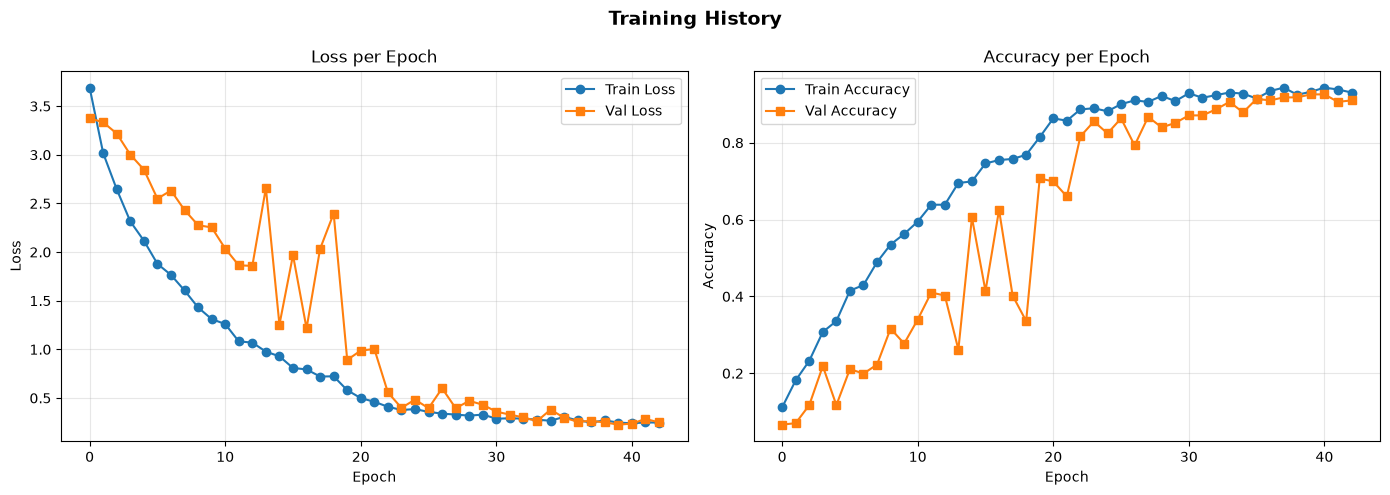

  Test Loss     : 0.2556
  Test Accuracy : 0.9187 (91.87%)

Classification Report:

              precision    recall  f1-score   support

           0       0.91      1.00      0.95        10
           1       1.00      0.90      0.95        10
           2       1.00      1.00      1.00        10
           3       1.00      0.90      0.95        10
           4       0.89      0.80      0.84        10
           5       1.00      1.00      1.00        10
           6       0.67      1.00      0.80        10
           7       1.00      0.60      0.75        10
           8       1.00      1.00      1.00        10
           9       1.00      1.00      1.00        10
          10       0.91      1.00      0.95        10
          11       0.83      1.00      0.91        10
          12       0.73      0.80      0.76        10
          13       1.00      0.80      0.89        10
          14       0.83      1.00      0.91        10
          15       0.75      0.60      0.67        

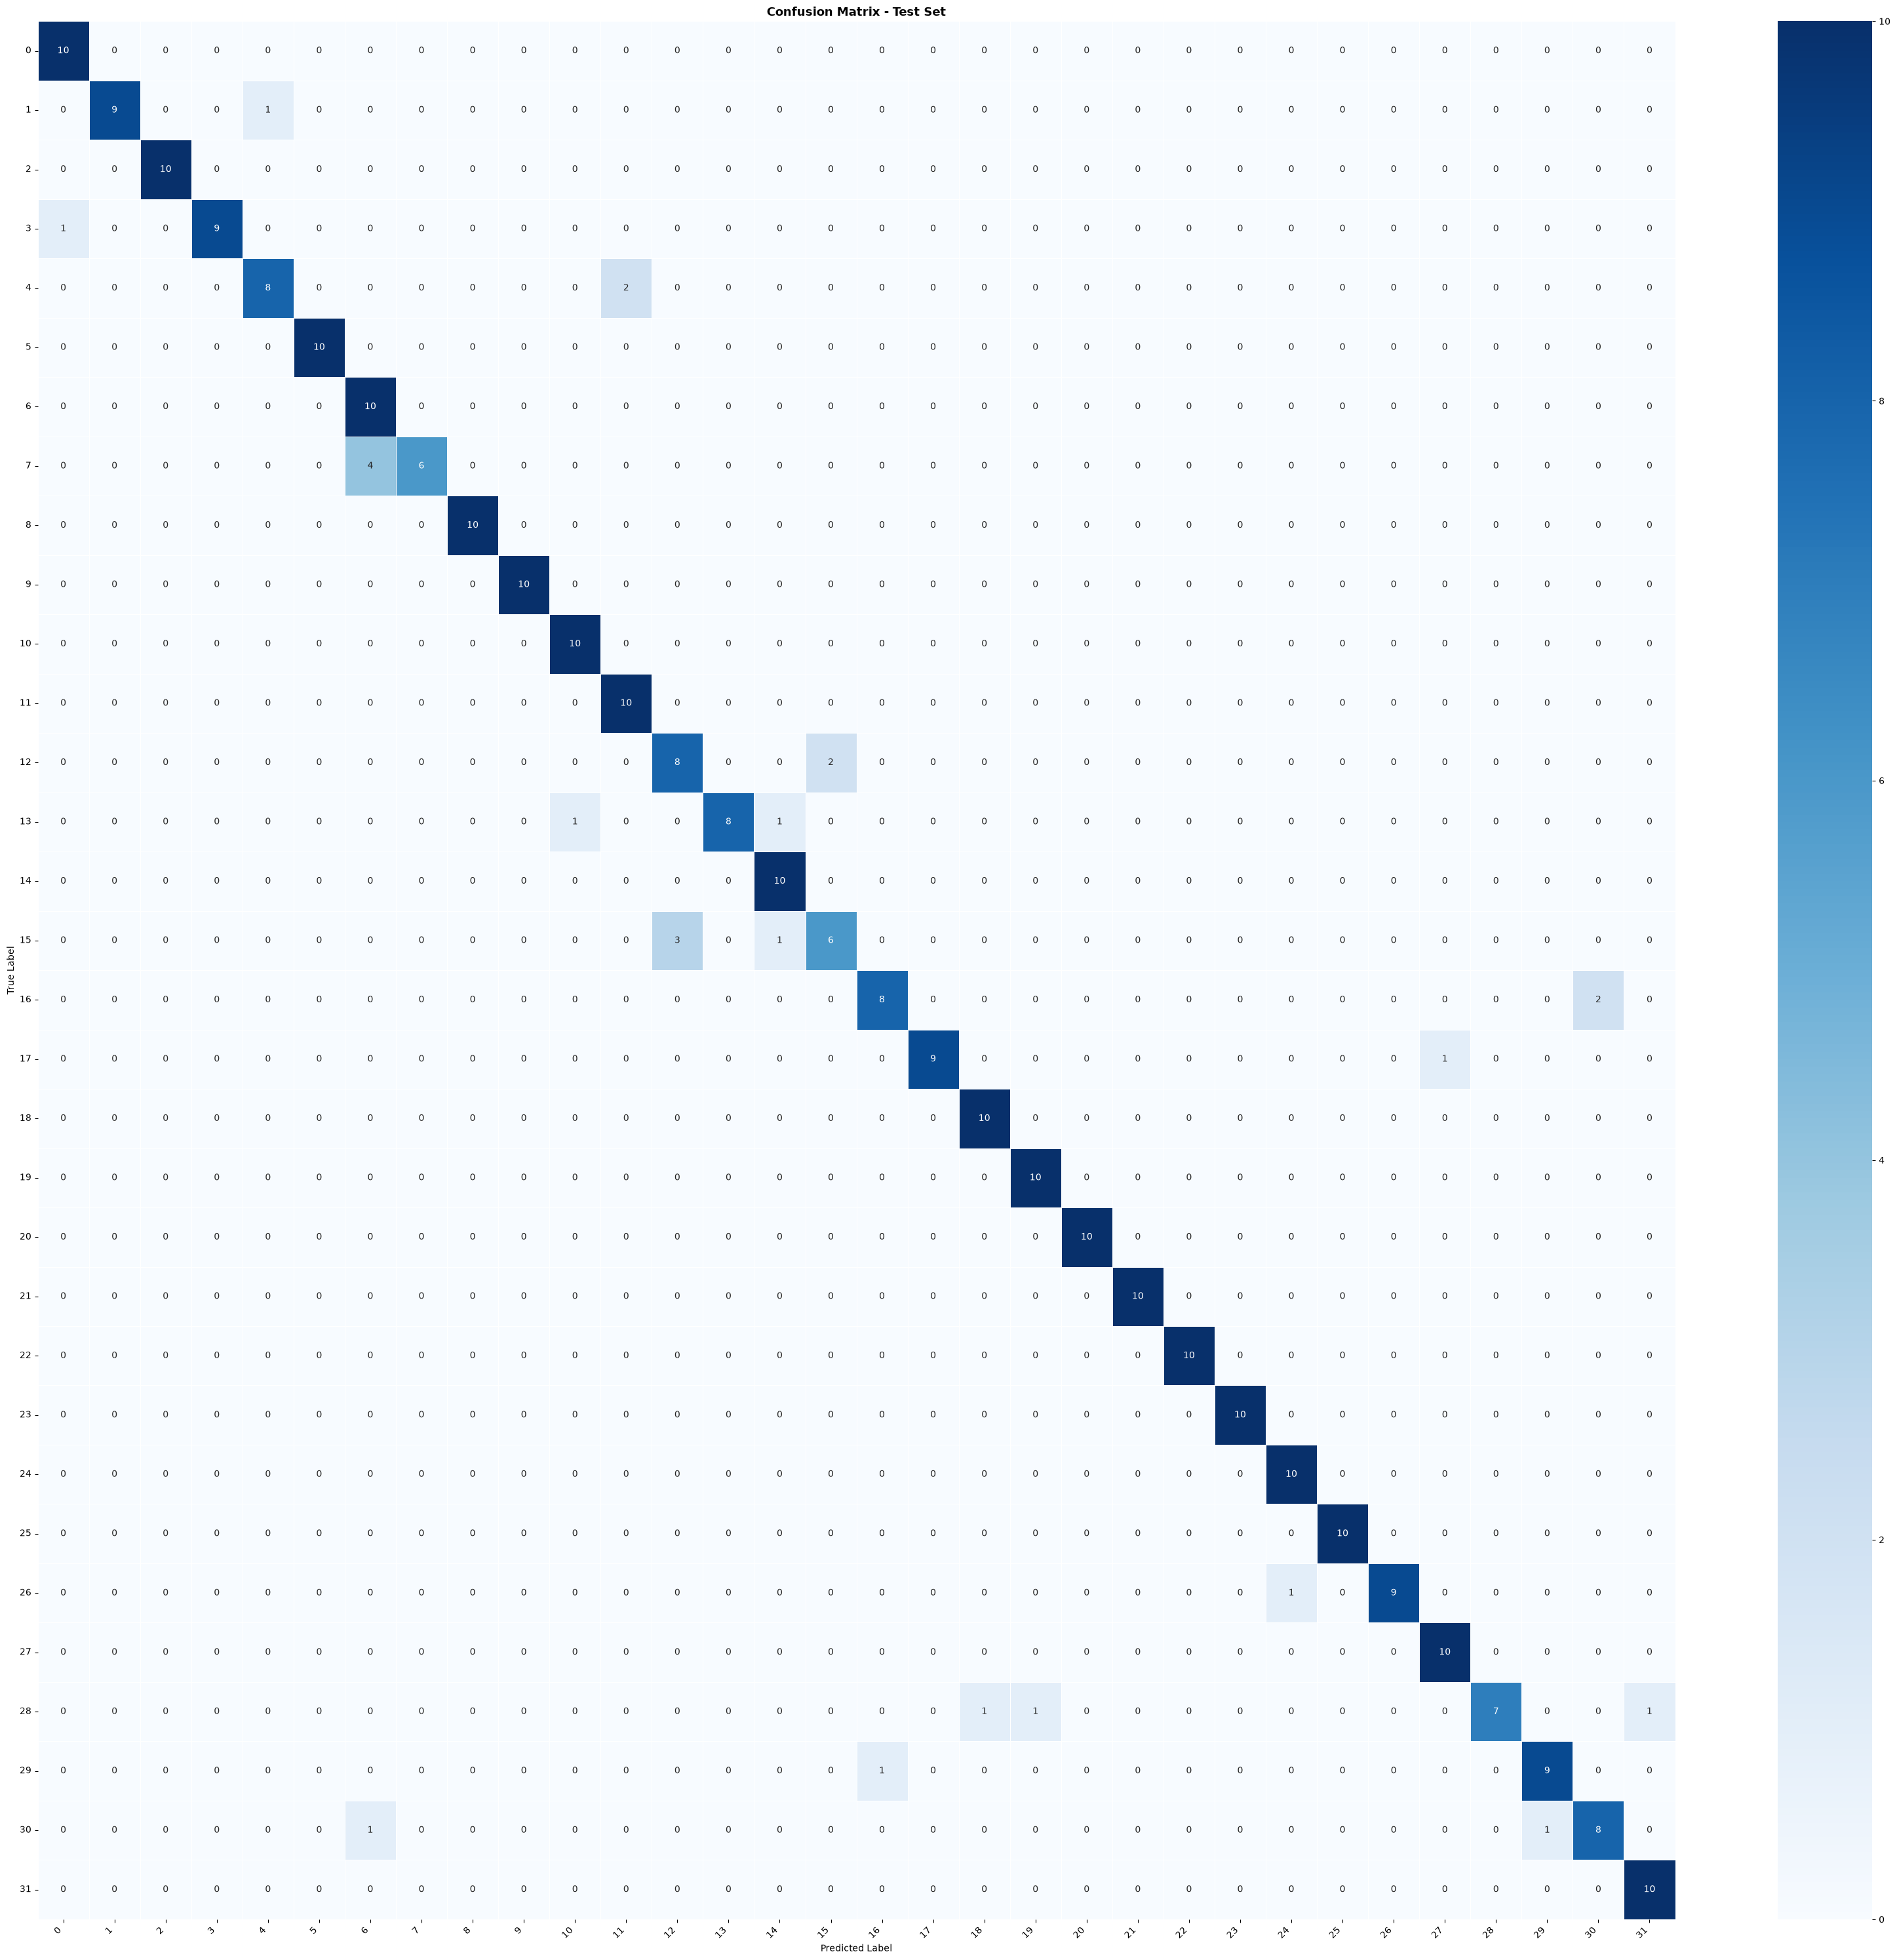

In [23]:
# ==========================================
# CELL 5B: EVALUASI MODEL
# ==========================================




# -- 1. Loss & Accuracy Curve
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Training History', fontsize=14, fontweight='bold')
axes[0].plot(history.history['loss'],     label='Train Loss',     marker='o')
axes[0].plot(history.history['val_loss'], label='Val Loss',       marker='s')
axes[0].set_title('Loss per Epoch')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)
axes[1].plot(history.history['accuracy'],     label='Train Accuracy', marker='o')
axes[1].plot(history.history['val_accuracy'], label='Val Accuracy',   marker='s')
axes[1].set_title('Accuracy per Epoch')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(str(MODEL_DIR / 'training_history.png'), dpi=150, bbox_inches='tight')
plt.show()

# -- 2. Evaluasi pada Test Set
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print('=' * 45)
print(f'  Test Loss     : {test_loss:.4f}')
print(f'  Test Accuracy : {test_acc:.4f} ({test_acc*100:.2f}%)')
print('=' * 45)

# -- 3. Prediksi & Classification Report
y_pred_proba = model.predict(X_test, verbose=0)
y_pred = np.argmax(y_pred_proba, axis=1)
print('\nClassification Report:\n')
print(classification_report(
    y_test, y_pred,
    target_names=[str(c) for c in class_names],
    zero_division=0
))

# -- 4. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sz = max(8, NUM_CLASSES)
plt.figure(figsize=(sz, sz - 2))
sns.heatmap(
    cm,
    annot=True, fmt='d',
    cmap='Blues',
    xticklabels=[str(c) for c in class_names],
    yticklabels=[str(c) for c in class_names],
    linewidths=0.5
)
plt.title('Confusion Matrix - Test Set', fontsize=13, fontweight='bold')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(str(MODEL_DIR / 'confusion_matrix.png'), dpi=150, bbox_inches='tight')
plt.show()


